# Environment Setup & Imports

In [ ]:
# pip3 install langchain langchain-openai langgraph pandas langchain_experimental python-dotenv tabulate scikit-learn==1.4.2 qdrant-client pypdf tiktoken langchain_community langchain_qdrant

import os
import pandas as pd
from typing import TypedDict, Annotated, Sequence
import operator

from langchain_openai import ChatOpenAI
from langchain_core.messages import BaseMessage, HumanMessage, SystemMessage
from langchain_experimental.agents.agent_toolkits import create_pandas_dataframe_agent
from langgraph.graph import StateGraph, END
from langchain.tools import tool
from langchain_core.messages import AIMessage
from typing import Literal

from dotenv import load_dotenv
load_dotenv()

# Initialize the core LLM
llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)

# Data Loading & The Analyst Agent Node

In [3]:
# Load the dataset
df = pd.read_csv("../datasets/WA_Fn-UseC_-HR-Employee-Attrition.csv")

# Create the internal Analyst Agent using the pandas toolkit
analyst_agent = create_pandas_dataframe_agent(
    llm, 
    df, 
    verbose=True, 
    allow_dangerous_code=True, # Required for local sandbox execution
    agent_type="openai-tools"
)

def data_analyst_node(state):
    """Node responsible for querying aggregate trends in the dataset."""
    messages = state["messages"]
    last_message = messages[-1].content
    
    # The agent executes python code in the background to answer the query
    response = analyst_agent.invoke({"input": last_message})
    
    return {"messages": [SystemMessage(content=f"Analyst Result: {response['output']}")]}

# The ML Predictor Tool

In [13]:
import pickle
import pandas as pd
from langchain.tools import tool

# 1. Load the models globally 
model = pickle.load(open('../models/model_2024_05_16.sav', 'rb'))
encoders = pickle.load(open('../models/encoder_2024_05_16.sav', 'rb'))

@tool
def predict_churn_probability(
    age_generation: str = 'Millennials', 
    business_travel: str = 'Travel_Rarely', 
    daily_rate: int = 800,
    department: str = 'Research & Development', 
    distance_from_home_category: str = 'Short Distance',
    education: str = 'Bachelor', 
    education_field: str = 'Life Sciences', 
    environment_satisfaction: str = 'High',
    gender: str = 'Male', 
    job_involvement: str = 'High',
    job_level: int = 2,
    job_role: Literal[
        'Sales Executive', 'Research Scientist', 'Laboratory Technician',
        'Manufacturing Director', 'Healthcare Representative', 'Manager',
        'Sales Representative', 'Research Director', 'Human Resources'
    ] = 'Sales Executive', 
    job_satisfaction: str = 'High', 
    marital_status: str = 'Married', 
    num_companies_worked: int = 1,
    overtime_preference: int = 0, 
    percent_salary_hike: int = 15,
    performance_rating: str = 'Excellent', 
    relationship_satisfaction: str = 'High', 
    stock_option_level: int = 1,
    total_working_years: int = 10, 
    training_times_last_year: int = 2, 
    work_life_balance: str = 'Good',
    years_at_company: int = 5, 
    years_in_current_role: int = 3, 
    years_since_last_promotion: int = 1,
    years_with_curr_manager: int = 3
) -> str:
    """
    Predicts the churn probability for a specific employee. 
    Use this ONLY when the user asks to predict or analyze a single individual's risk.
    """
    
    # 2. Map the tool arguments to your exact app.py feature list
    features = [
        'AgeGeneration', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHomeCategory',
        'Education', 'EducationField', 'EnvironmentSatisfaction', 'Gender', 'JobInvolvement',
        'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'NumCompaniesWorked',
        'Overtime_Preference', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 
        'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance',
        'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager'
    ]

    values_to_predict = [
        age_generation, business_travel, daily_rate, department, distance_from_home_category, 
        education, education_field, environment_satisfaction, gender, job_involvement, 
        job_level, job_role, job_satisfaction, marital_status, num_companies_worked, 
        overtime_preference, percent_salary_hike, performance_rating, relationship_satisfaction, 
        stock_option_level, total_working_years, training_times_last_year, work_life_balance, 
        years_at_company, years_in_current_role, years_since_last_promotion, years_with_curr_manager
    ]

    # 3. Build the DataFrame and apply your loaded label encoders
    df_to_predict = pd.DataFrame(values_to_predict, index=features).T

    for col in encoders.keys():
        if (col != 'Attrition') and (col != 'OverTime') and (col in df_to_predict.columns):
            df_to_predict[col] = encoders[col].transform(df_to_predict[col])

    # 4. Run the model prediction
    pred_proba = model.predict_proba(df_to_predict)
    active_proba = float(pred_proba[0][0])
    churn_proba = float(pred_proba[0][1])

    return f"Prediction Breakdown: {active_proba * 100:.2f}% Stay, {churn_proba * 100:.2f}% Churn."


# Bind the updated tool to the LLM
predictor_llm = llm.bind_tools([predict_churn_probability])

def predictor_node(state):
    """Node responsible for executing the scikit-learn model on single employees."""
    messages = state["messages"]
    
    # 1. The LLM processes the prompt and decides to call the tool
    response = predictor_llm.invoke(messages)
    
    # 2. Check if the LLM successfully generated a tool call
    if response.tool_calls:
        # Extract the specific tool call data
        tool_call = response.tool_calls[0]
        
        # 3. Actually execute the LangChain tool using the LLM's arguments
        prediction_result = predict_churn_probability.invoke(tool_call["args"])
        
        # 4. Return the result as a standard AI message for the Streamlit UI
        return {"messages": [AIMessage(content=prediction_result)]}
    
    # Fallback if the LLM decides to just chat normally without calling the tool
    return {"messages": [response]}

# The Supervisor Router (System 1 Thinking)

In [14]:
def supervisor_router(state) -> str:
    """Evaluates the state and routes to the correct sub-agent."""
    messages = state["messages"]
    last_message = messages[-1].content.lower()
    
    # Simple routing logic (can be upgraded to a structured LLM call later)
    if "average" in last_message or "how many" in last_message or "compare" in last_message or "dataset" in last_message:
        return "analyst"
    elif "predict" in last_message or "probability" in last_message or "risk" in last_message:
        return "predictor"
    else:
        return "end"

# Graph Compilation

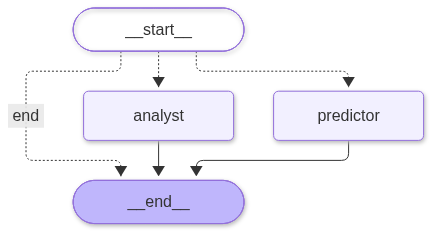

In [15]:
from IPython.display import Image, display

#  Define the memory state
class AgentState(TypedDict):
    messages: Annotated[Sequence[BaseMessage], operator.add]

# Initialize the graph
workflow = StateGraph(AgentState)

# Add our nodes
workflow.add_node("analyst", data_analyst_node)
workflow.add_node("predictor", predictor_node)

# Set the entry point to the router
workflow.set_conditional_entry_point(
    supervisor_router,
    {
        "analyst": "analyst",
        "predictor": "predictor",
        "end": END
    }
)

# After a node finishes, end the cycle (until we add the RAG and HITL nodes)
workflow.add_edge("analyst", END)
workflow.add_edge("predictor", END)

# Compile the graph
hr_copilot = workflow.compile()


# Generate and display the graph directly within the Jupyter Notebook cell
try:
    display(Image(hr_copilot.get_graph().draw_mermaid_png()))
except Exception as e:
    print(f"Error generating graph image: {e}")
    # Fallback to outputting the raw Mermaid syntax if the PNG renderer fails
    print(hr_copilot.get_graph().draw_mermaid())

# Testing the Workflow

In [17]:
# Test 1: Macro-level analysis (Routes to Analyst Agent)
macro_query = "What is the average TotalWorkingYears for employees in the Sales department?"
result_macro = hr_copilot.invoke({"messages": [HumanMessage(content=macro_query)]})
print("Macro Response:", result_macro["messages"][-1].content)

print("-" * 50)

# Test 2: Individual Prediction (Routes to ML Predictor)
micro_query = "Predict the churn probability for a Gen Z employee with 2 TotalWorkingYears working as a Sales Representative."
result_micro = hr_copilot.invoke({"messages": [HumanMessage(content=micro_query)]})

# CHANGE THIS LINE to .content
print("Micro Response:", result_micro["messages"][-1].content)



> Entering new AgentExecutor chain...

Invoking: `python_repl_ast` with `{'query': "average_total_working_years = df[df['Department'] == 'Sales']['TotalWorkingYears'].mean()\naverage_total_working_years"}`


11.105381165919283The average TotalWorkingYears for employees in the Sales department is approximately 11.11 years.

> Finished chain.
Macro Response: Analyst Result: The average TotalWorkingYears for employees in the Sales department is approximately 11.11 years.
--------------------------------------------------
Micro Response: Prediction Breakdown: 45.82% Stay, 54.18% Churn.


# Ingestion and Embedding

In [25]:
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_openai import OpenAIEmbeddings
from langchain_qdrant import QdrantVectorStore # <--- Use this instead of Qdrant
from qdrant_client import QdrantClient
from qdrant_client.http.models import Distance, VectorParams

# 1. Load the generated PDF
loader = PyPDFLoader("../datasets/Mock Employee Retention & HR Policy Playbook.pdf")
docs = loader.load()

# 2. Split the document into semantic chunks
text_splitter = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=150)
splits = text_splitter.split_documents(docs)

# 3. Initialize embeddings
embeddings = OpenAIEmbeddings(model="text-embedding-3-small")

# 4. Initialize local in-memory Qdrant client
client = QdrantClient(":memory:")
client.create_collection(
    collection_name="hr_policies",
    vectors_config=VectorParams(size=1536, distance=Distance.COSINE),
)

# 5. Store in local Qdrant Vector Database
vectorstore = QdrantVectorStore(
    client=client,
    collection_name="hr_policies",
    embedding=embeddings,
)
vectorstore.add_documents(splits)

# 6. Create a retriever that fetches the top 3 most relevant policy chunks
policy_retriever = vectorstore.as_retriever(search_kwargs={"k": 3})

# RAG Node

In [26]:
def rag_node(state):
    """Node responsible for querying the Qdrant vector store for HR policies."""
    messages = state["messages"]
    last_message = messages[-1].content
    
    # 1. Retrieve the relevant chunks from Qdrant
    retrieved_docs = policy_retriever.invoke(last_message)
    context = "\n\n".join(doc.page_content for doc in retrieved_docs)
    
    # 2. Construct a strict prompt incorporating the DOLE/Philippine context
    rag_prompt = f"""You are a Philippine HR Retention Expert. 
    Answer the user's question based strictly on the provided HR Playbook context.
    If the answer is not in the context, state clearly that the policy does not cover it.
    
    Context:
    {context}
    
    Question: {last_message}"""
    
    # 3. Generate the grounded response
    response = llm.invoke(rag_prompt)
    
    from langchain_core.messages import AIMessage
    return {"messages": [AIMessage(content=f"Policy Recommendation:\n{response.content}")]}

# Recompiling the Supervisor Workflow

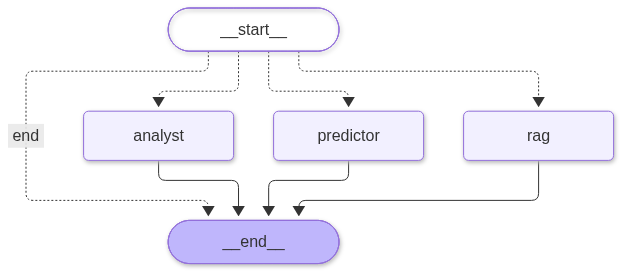

In [27]:
# 1. Update the router to include the RAG pathway
def supervisor_router(state) -> str:
    """Evaluates the state and routes to the correct sub-agent."""
    messages = state["messages"]
    last_message = messages[-1].content.lower()
    
    if "average" in last_message or "how many" in last_message or "compare" in last_message:
        return "analyst"
    elif "predict" in last_message or "probability" in last_message or "risk" in last_message:
        return "predictor"
    elif "policy" in last_message or "handbook" in last_message or "retention" in last_message or "hike" in last_message or "promote" in last_message:
        return "rag"
    else:
        return "end"

# 2. Re-initialize the graph
workflow = StateGraph(AgentState)

# 3. Add all three nodes
workflow.add_node("analyst", data_analyst_node)
workflow.add_node("predictor", predictor_node)
workflow.add_node("rag", rag_node)  # NEW

# 4. Map the router
workflow.set_conditional_entry_point(
    supervisor_router,
    {
        "analyst": "analyst",
        "predictor": "predictor",
        "rag": "rag",       # NEW
        "end": END
    }
)

# 5. End cycles
workflow.add_edge("analyst", END)
workflow.add_edge("predictor", END)
workflow.add_edge("rag", END)       # NEW

# 6. Compile
hr_copilot = workflow.compile()

# Generate and display the graph directly within the Jupyter Notebook cell
try:
    display(Image(hr_copilot.get_graph().draw_mermaid_png()))
except Exception as e:
    print(f"Error generating graph image: {e}")
    # Fallback to outputting the raw Mermaid syntax if the PNG renderer fails
    print(hr_copilot.get_graph().draw_mermaid())

# Testing the RAG Pipeline

In [28]:
# Test 3: Policy Retrieval (Routes to RAG Node)
rag_query = "What is our official retention policy regarding salary hikes for employees who have been in their current role for over 5 years?"
result_rag = hr_copilot.invoke({"messages": [HumanMessage(content=rag_query)]})
print("RAG Response:\n", result_rag["messages"][-1].content)

RAG Response:
 Policy Recommendation:
The policy does not cover salary hikes specifically for employees who have been in their current role for over 5 years. However, it does mention that if an employee's YearsInCurrentRole reaches 3 years without a formal promotion, their direct manager must initiate a "Career Crossroads" dialogue, which may include offering an Acting Capacity Role with OIC pay. For salary hikes, the policy states that if the PercentSalaryHike is less than 8%, an off-cycle merit and inflation adjustment of 10-15% should be triggered.
